# 03 — Intelligent World Discretization (Google S2 & Country-Aware Partitioning)

In **Timeguessr AI**, predicting exact `(latitude, longitude)` directly via regression tends to collapse toward geographic averages (often landing in oceans) when an image is ambiguous. Instead, following **PlaNet** (Weyand et al.), **ISNs** (Müller-Budack et al.), and **PIGEON** (Haas et al.), we frame geolocation as **classification over discrete geographic tiles**.

This notebook designs, evaluates, and exports **two complementary, intelligent world discretizations** (across multiple granularities as a hyperparameter for Notebook 04):

1. **Strategy A — Multi-Scale Adaptive Google S2 Quadtree (`s2_coarse`, `s2_medium`, `s2_fine`)**
   - Recursively subdivides Google S2 spherical cells (`s2sphere`) where **country-balanced** training density is high, while keeping oceans, deserts, and sparse regions coarse.
   - Builds **3 granularities** (`coarse` ~250 tiles, `medium` ~800–1,000 tiles, `fine` ~2,000–2,500 tiles) so Notebook 04 can sweep tile count as a hyperparameter *or* train a multi-scale hierarchical space head.
   - Replaces naive S2 geometric centers (which often fall in the ocean for coastal cities) with **data-weighted 3D spherical centroids**.

2. **Strategy B — Country-Aware Semantic Partitioning (`semantic_medium`)**
   - Addresses a core limitation of raw S2 tiles: geometric cell boundaries cut across national borders and split cities, blurring country-level visual cues (road signs, scripts, license plates) and making **Notebook 05's OCR language masking** ambiguous.
   - Partitions **within each country** using sublinear cluster allocation + **Spherical K-Means** on 3D unit-sphere coordinates. Small countries remain clean single-country tiles, while large/dense countries split into coherent city/regional tiles with **100% single-country purity**.

> **Zero Leakage Design:** All partitions are fitted strictly on the external training pool (`OSV-5M` + `PastVu` + `PastVu-NonRU` + `YFCC15M` + `YFCC-Pre2000` + `Wikimedia`). The local `Timeguessr` daily challenge dataset (`data/images/Timeguessr/`) is held out purely to measure each discretization's **oracle ceiling score** and **quantization error**.

## 1. Setup & Load Unified Datasets

In [24]:
import json
import math
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.collections import PatchCollection
import numpy as np
import pandas as pd
import reverse_geocoder as rg
import s2sphere
from scipy.spatial import cKDTree
from sklearn.cluster import MiniBatchKMeans, KMeans

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
IMAGES_DIR = DATA_DIR / "images"
TILING_DIR = DATA_DIR / "tiling"
TILING_DIR.mkdir(parents=True, exist_ok=True)

EARTH_RADIUS_KM = 6371.0088
SEED = 42
np.random.seed(SEED)

print(f"Project root: {PROJECT_ROOT}")
print(f"Tiling out:   {TILING_DIR}")

Project root: d:\VSCodeProjects\CS441
Tiling out:   d:\VSCodeProjects\CS441\data\tiling


In [25]:
def load_local_timeguessr(base_dir: Path) -> pd.DataFrame:
    meta_csv = base_dir / "metadata.csv"
    if meta_csv.exists():
        df = pd.read_csv(meta_csv)
        if {"image_path", "year", "latitude", "longitude"}.issubset(df.columns):
            df["source"] = "timeguessr"
            return df

    records = []
    for img_path in sorted(base_dir.rglob("*")):
        if img_path.suffix.lower() not in (".jpg", ".jpeg", ".png", ".webp"):
            continue
        parts = img_path.stem.split("_")
        if len(parts) < 3:
            continue
        try:
            year = int(parts[0])
            lat = float(parts[1])
            lon = float(parts[2])
        except ValueError:
            continue
        records.append({
            "image_path": str(img_path.relative_to(PROJECT_ROOT)),
            "year": year,
            "latitude": lat,
            "longitude": lon,
            "source": "timeguessr",
        })
    return pd.DataFrame(records)


def ensure_country_column(df: pd.DataFrame) -> pd.DataFrame:
    """Fill missing ISO-2 country codes via offline reverse_geocoder (mode=1 for Windows safety)."""
    df = df.copy()
    if "country" not in df.columns:
        df["country"] = None
    missing_mask = df["country"].isna() | (df["country"].astype(str).str.len() != 2)
    if missing_mask.any():
        coords = list(zip(df.loc[missing_mask, "latitude"], df.loc[missing_mask, "longitude"]))
        results = rg.search(coords, mode=1)
        df.loc[missing_mask, "country"] = [r.get("cc", "XX") for r in results]
    df["country"] = df["country"].astype(str).str.upper()
    return df


def clean_geo_df(df: pd.DataFrame, source_name: str) -> pd.DataFrame:
    keep_cols = [c for c in ["image_path", "year", "latitude", "longitude", "country", "source"] if c in df.columns]
    out = df[keep_cols].copy()
    out["source"] = source_name
    out["latitude"] = pd.to_numeric(out["latitude"], errors="coerce")
    out["longitude"] = pd.to_numeric(out["longitude"], errors="coerce")
    out["year"] = pd.to_numeric(out["year"], errors="coerce")
    out = out.dropna(subset=["latitude", "longitude", "year"]).copy()
    out = out[
        out["latitude"].between(-90.0, 90.0)
        & out["longitude"].between(-180.0, 180.0)
        & ~((out["latitude"] == 0.0) & (out["longitude"] == 0.0))
    ].copy()
    out["year"] = out["year"].astype(int)
    return ensure_country_column(out)


osv_df = clean_geo_df(pd.read_csv(IMAGES_DIR / "osv5m" / "metadata_balanced.csv"), "osv5m")
pastvu_df = clean_geo_df(pd.read_csv(IMAGES_DIR / "pastvu" / "metadata.csv"), "pastvu")

pastvu_non_ru_path = IMAGES_DIR / "pastvu_non_ru" / "metadata.csv"
pastvu_non_ru_df = (
    clean_geo_df(pd.read_csv(pastvu_non_ru_path), "pastvu_non_ru")
    if pastvu_non_ru_path.exists()
    else pd.DataFrame(columns=pastvu_df.columns)
)

yfcc_df = clean_geo_df(pd.read_csv(IMAGES_DIR / "yfcc15m" / "metadata_downloaded.csv"), "yfcc15m")

yfcc_pre2000_path = IMAGES_DIR / "yfcc15m_pre2000" / "metadata_downloaded.csv"
yfcc_pre2000_df = (
    clean_geo_df(pd.read_csv(yfcc_pre2000_path), "yfcc15m_pre2000")
    if yfcc_pre2000_path.exists()
    else pd.DataFrame(columns=yfcc_df.columns)
)

wikimedia_path = IMAGES_DIR / "wikimedia" / "metadata_downloaded.csv"
wikimedia_df = (
    clean_geo_df(pd.read_csv(wikimedia_path), "wikimedia")
    if wikimedia_path.exists()
    else pd.DataFrame(columns=yfcc_df.columns)
)

tg_df = clean_geo_df(load_local_timeguessr(IMAGES_DIR / "Timeguessr"), "timeguessr")

external_parts = [df for df in (osv_df, pastvu_df, pastvu_non_ru_df, yfcc_df, yfcc_pre2000_df, wikimedia_df) if len(df) > 0]
train_pool_df = pd.concat(external_parts, ignore_index=True)

print("=== Dataset Geographic Summary ===")
summary_rows = [
    ("OSV-5M", osv_df),
    ("PastVu", pastvu_df),
    ("PastVu-NonRU", pastvu_non_ru_df),
    ("YFCC15M", yfcc_df),
    ("YFCC-Pre2000", yfcc_pre2000_df),
    ("Wikimedia", wikimedia_df),
    ("Train Pool", train_pool_df),
    ("Timeguessr (Eval)", tg_df),
]
for name, df in summary_rows:
    if len(df) == 0:
        continue
    top_cc = df["country"].value_counts().head(3).to_dict()
    print(
        f"{name:18s} | n={len(df):7,d} | countries={df['country'].nunique():3d} | "
        f"lat=[{df['latitude'].min():6.2f}, {df['latitude'].max():5.2f}] | "
        f"lon=[{df['longitude'].min():7.2f}, {df['longitude'].max():6.2f}] | top3={top_cc}"
    )

=== Dataset Geographic Summary ===
OSV-5M             | n= 25,000 | countries=217 | lat=[-51.70, 78.66] | lon=[-176.33, 178.47] | top3={'US': 719, 'DE': 441, 'FR': 426}
PastVu             | n= 12,016 | countries=  9 | lat=[ 37.94, 60.20] | lon=[  -0.13,  87.10] | top3={'RU': 12000, 'UA': 7, 'TM': 3}
PastVu-NonRU       | n= 15,000 | countries= 63 | lat=[-37.93, 78.12] | lon=[-157.83, 179.20] | top3={'UA': 4113, 'DE': 1933, 'US': 1597}
YFCC15M            | n= 22,281 | countries=200 | lat=[-88.85, 89.85] | lon=[-179.88, 179.37] | top3={'US': 2538, 'GB': 974, 'CA': 629}
YFCC-Pre2000       | n= 12,851 | countries=152 | lat=[-77.88, 71.06] | lon=[-176.63, 178.02] | top3={'US': 2844, 'GB': 1410, 'CA': 877}
Wikimedia          | n=  9,492 | countries= 97 | lat=[-44.77, 68.09] | lon=[-149.90, 178.47] | top3={'IN': 394, 'BR': 393, 'KR': 366}
Train Pool         | n= 96,640 | countries=240 | lat=[-88.85, 89.85] | lon=[-179.88, 179.37] | top3={'RU': 12751, 'US': 7906, 'UA': 4223}
Timeguessr (Eval)  

## 2. Spherical Math, Timeguessr Scoring Metric & Oracle Evaluation Harness

To compare discretizations objectively, we evaluate each partition's **oracle ceiling** on the held-out `Timeguessr` benchmark: *if our ViT classifier predicted the ground-truth tile 100% of the time, what quantization error (km) and Timeguessr location score (out of 5,000) would it achieve?*

This directly measures the **granularity vs. learnability tradeoff**:
- Too few tiles → low oracle score ceiling (tiles are too huge).
- Too many tiles → high oracle score, but too few training images per tile for the ViT space head to generalize.

In [26]:
def latlon_to_xyz(lat_deg: np.ndarray, lon_deg: np.ndarray) -> np.ndarray:
    """Convert latitude/longitude (degrees) to 3D unit-sphere vectors (N, 3)."""
    lat = np.radians(lat_deg)
    lon = np.radians(lon_deg)
    cos_lat = np.cos(lat)
    return np.column_stack([cos_lat * np.cos(lon), cos_lat * np.sin(lon), np.sin(lat)])


def xyz_to_latlon(xyz: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Convert 3D vectors to (lat_deg, lon_deg)."""
    xyz = np.atleast_2d(xyz)
    norms = np.linalg.norm(xyz, axis=1, keepdims=True)
    xyz = xyz / np.maximum(norms, 1e-12)
    lat = np.degrees(np.arcsin(np.clip(xyz[:, 2], -1.0, 1.0)))
    lon = np.degrees(np.arctan2(xyz[:, 1], xyz[:, 0]))
    return lat, lon


def spherical_centroid(lat_deg: np.ndarray, lon_deg: np.ndarray, weights: np.ndarray | None = None) -> tuple[float, float]:
    """Compute weighted 3D spherical mean (avoids antimeridian wrap-around and polar distortion)."""
    xyz = latlon_to_xyz(lat_deg, lon_deg)
    if weights is None:
        mean_vec = xyz.mean(axis=0)
    else:
        w = np.asarray(weights, dtype=np.float64)
        mean_vec = (xyz * w[:, None]).sum(axis=0) / max(w.sum(), 1e-12)
    if np.linalg.norm(mean_vec) < 1e-12:
        return float(np.mean(lat_deg)), float(np.mean(lon_deg))
    lat_c, lon_c = xyz_to_latlon(mean_vec[None, :])
    return float(lat_c[0]), float(lon_c[0])


def haversine_km(lat1, lon1, lat2, lon2) -> np.ndarray:
    """Vectorized great-circle distance in kilometers."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    return 2.0 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0)))


def timeguessr_location_score(dist_km: np.ndarray) -> np.ndarray:
    d = np.maximum(np.asarray(dist_km, dtype=np.float64) - 0.05, 0.0)
    score = 5000.0 * np.exp(-((d / 6000.0) ** 0.62) - ((d / 3000.0) ** 1.5))
    return np.clip(np.rint(score), 0.0, 5000.0)


def evaluate_partition(
    name: str,
    cells_df: pd.DataFrame,
    eval_df: pd.DataFrame,
    eval_tile_ids: np.ndarray,
    use_geom_center: bool = False,
) -> dict:
    """Compute oracle quantization error, Timeguessr score ceiling, and tile balance metrics."""
    lat_col = "geom_lat" if (use_geom_center and "geom_lat" in cells_df.columns) else "centroid_lat"
    lon_col = "geom_lon" if (use_geom_center and "geom_lon" in cells_df.columns) else "centroid_lon"

    tile_lookup = cells_df.set_index("tile_id")
    pred_lat = tile_lookup.loc[eval_tile_ids, lat_col].to_numpy()
    pred_lon = tile_lookup.loc[eval_tile_ids, lon_col].to_numpy()

    dists = haversine_km(eval_df["latitude"].to_numpy(), eval_df["longitude"].to_numpy(), pred_lat, pred_lon)
    scores = timeguessr_location_score(dists)

    # Single-country purity: fraction of tiles where >= 95% of training samples share one country
    purity_pct = float((cells_df["country_purity"] >= 0.95).mean() * 100.0) if "country_purity" in cells_df.columns else np.nan

    return {
        "partition": name,
        "num_tiles": len(cells_df),
        "train_min": int(cells_df["train_count"].min()),
        "train_median": float(cells_df["train_count"].median()),
        "train_max": int(cells_df["train_count"].max()),
        "country_purity_pct": round(purity_pct, 1),
        "tg_median_err_km": round(float(np.median(dists)), 1),
        "tg_mean_err_km": round(float(np.mean(dists)), 1),
        "tg_oracle_median_score": round(float(np.median(scores)), 1),
        "tg_oracle_mean_score": round(float(np.mean(scores)), 1),
        "tg_within_25km_pct": round(float((dists <= 25.0).mean() * 100.0), 1),
        "tg_within_200km_pct": round(float((dists <= 200.0).mean() * 100.0), 1),
        "tg_within_750km_pct": round(float((dists <= 750.0).mean() * 100.0), 1),
        "_dists": dists,
        "_scores": scores,
    }

## 3. Country-Balanced Sample Weighting (Fixing PastVu Regional Skew)

Look closely at the dataset summary above: **PastVu** (`n=14,250`) is geographically concentrated almost entirely in Western Russia / Eastern Europe (`lat=[46.45, 61.04], lon=[28.21, 55.07]`).

If we split S2 cells using raw unweighted sample counts, Russia alone would consume ~25% of all fine tiles in the world! To mirror real Timeguessr geography (and human player priors), we assign each training sample a **sublinear country-balanced splitting weight**:
$$w_i \propto n_{c(i)}^{\alpha - 1}, \quad \alpha = 0.6$$
normalized so $\sum_i w_i = N_{\text{train}}$ (consistent with Notebook 01's `COUNTRY_ALPHA = 0.6`).

In [27]:
SPLIT_COUNTRY_ALPHA = 0.7

country_counts = train_pool_df["country"].value_counts()
raw_weights = train_pool_df["country"].map(lambda c: country_counts[c] ** (SPLIT_COUNTRY_ALPHA - 1.0)).to_numpy(dtype=np.float64)
# Normalize so total effective weight equals total number of training samples
split_weights = raw_weights * (len(train_pool_df) / raw_weights.sum())
train_pool_df["split_weight"] = split_weights

# Verify how Russia's share changes before vs. after balanced weighting
before_share = (train_pool_df["country"].value_counts(normalize=True).head(8) * 100).round(2)
after_share = (train_pool_df.groupby("country")["split_weight"].sum().sort_values(ascending=False).head(8) / len(train_pool_df) * 100).round(2)

comparison = pd.DataFrame({"raw_pct": before_share, "balanced_weight_pct": after_share}).fillna(0)
print("Top countries by raw sample share vs. balanced splitting weight share:")
display(comparison)

Top countries by raw sample share vs. balanced splitting weight share:


,raw_pct,balanced_weight_pct
country,,
RU,13.19,6.03
US,8.18,4.31
UA,4.37,2.78
DE,4.03,2.62
GB,3.11,2.19
FR,2.92,2.10
CA,2.04,1.63
CH,1.78,1.48


## 4. Strategy A — Multi-Scale Adaptive Google S2 Quadtree

Using `s2sphere`, the Earth's surface is projected onto the 6 faces of a cube (`level 0`), where each cell recursively splits into 4 children up to `level 30`. Our adaptive quadtree algorithm:

1. Starts from the 6 root S2 faces (`level 0`) and recursively subdivides any cell whose **balanced effective weight** exceeds `tau_max` (and has at least `2 * tau_min` raw samples), up to `max_level`.
2. **Prunes sparse children** (`raw_count < tau_min`): a split is accepted only if at least 2 children meet `tau_min`, guaranteeing every tile has enough training images for the ViT classifier to learn from.
3. Any training points in pruned sparse sibling cells are assigned to their **nearest surviving tile centroid** on the 3D unit sphere, so **zero training data is discarded**.
4. Stores **both** the geometric S2 cell center (`geom_lat, geom_lon`) and the **data-weighted spherical centroid** (`centroid_lat, centroid_lon`), plus each tile's country distribution for Notebook 05's OCR language masking.
5. At inference time (`assign_points`), performs fast $O(L)$ S2 prefix lookup from `max_level` down to `min_level`, with a 3D `cKDTree` nearest-centroid fallback for any query point landing in an ocean/unpopulated cell.

In [28]:
class AdaptiveS2Partition:
    """Adaptive Google S2 quadtree partition with spherical centroids and fast lookup."""

    def __init__(self, name: str, cells_df: pd.DataFrame, max_level: int):
        self.name = name
        self.cells_df = cells_df.reset_index(drop=True)
        self.max_level = max_level
        self.min_level = int(self.cells_df["s2_level"].min())
        self.token_to_id = dict(zip(self.cells_df["s2_token"], self.cells_df["tile_id"]))
        self.cellid_to_id = {
            s2sphere.CellId.from_token(tok).id(): int(tid)
            for tok, tid in zip(self.cells_df["s2_token"], self.cells_df["tile_id"])
        }
        self.centroid_xyz = latlon_to_xyz(
            self.cells_df["centroid_lat"].to_numpy(),
            self.cells_df["centroid_lon"].to_numpy(),
        )
        self.kdtree = cKDTree(self.centroid_xyz)
        self.tile_ids = self.cells_df["tile_id"].to_numpy()

    def assign_points(self, lats: np.ndarray, lons: np.ndarray) -> np.ndarray:
        """Assign (lat, lon) arrays to tile_ids using S2 ancestor lookup + spherical KD-tree fallback."""
        lats = np.asarray(lats, dtype=np.float64)
        lons = np.asarray(lons, dtype=np.float64)
        out = np.full(len(lats), -1, dtype=np.int32)
        fallback_idx = []

        cellid_map = self.cellid_to_id
        max_lvl = self.max_level
        min_lvl = self.min_level

        for i in range(len(lats)):
            cid = s2sphere.CellId.from_lat_lng(s2sphere.LatLng.from_degrees(lats[i], lons[i])).parent(max_lvl)
            found = -1
            cur = cid
            for lvl in range(max_lvl, min_lvl - 1, -1):
                tid = cellid_map.get(cur.id())
                if tid is not None:
                    found = tid
                    break
                if lvl > min_lvl:
                    cur = cur.parent(lvl - 1)
            if found != -1:
                out[i] = found
            else:
                fallback_idx.append(i)

        if fallback_idx:
            fb = np.asarray(fallback_idx, dtype=np.int64)
            fb_xyz = latlon_to_xyz(lats[fb], lons[fb])
            _, nn = self.kdtree.query(fb_xyz)
            out[fb] = self.tile_ids[nn]

        return out


def build_adaptive_s2_partition(
    df: pd.DataFrame,
    name: str,
    tau_max: float,
    tau_min: int = 15,
    min_level: int = 2,
    max_level: int = 12,
) -> AdaptiveS2Partition:
    """Build an adaptive S2 quadtree partition using balanced sample weights."""
    lats = df["latitude"].to_numpy(dtype=np.float64)
    lons = df["longitude"].to_numpy(dtype=np.float64)
    weights = df["split_weight"].to_numpy(dtype=np.float64)
    countries = df["country"].to_numpy()

    # Precompute leaf S2 CellIds at max_level once
    leaf_cids = [
        s2sphere.CellId.from_lat_lng(s2sphere.LatLng.from_degrees(lat, lon)).parent(max_level)
        for lat, lon in zip(lats, lons)
    ]

    # Group indices by root cells at min_level
    root_groups: dict[s2sphere.CellId, list[int]] = defaultdict(list)
    for idx, cid in enumerate(leaf_cids):
        root_groups[cid.parent(min_level)].append(idx)

    surviving_cells: list[tuple[s2sphere.CellId, np.ndarray]] = []
    orphaned_indices: list[int] = []

    def _split(cell_id: s2sphere.CellId, idxs: np.ndarray):
        lvl = cell_id.level()
        w_sum = float(weights[idxs].sum())
        if lvl >= max_level or w_sum <= tau_max or len(idxs) < 2 * tau_min:
            surviving_cells.append((cell_id, idxs))
            return

        # Partition points into the 4 S2 children at lvl + 1
        child_buckets: dict[s2sphere.CellId, list[int]] = defaultdict(list)
        next_lvl = lvl + 1
        for i in idxs:
            child_buckets[leaf_cids[i].parent(next_lvl)].append(i)

        valid_children = [(c, np.asarray(v, dtype=np.int64)) for c, v in child_buckets.items() if len(v) >= tau_min]
        if len(valid_children) < 2:
            # Splitting wouldn't yield >= 2 well-populated tiles; keep parent cell
            surviving_cells.append((cell_id, idxs))
            return

        # Record any sparse sibling points (< tau_min) so they can be reassigned cleanly
        for c, v in child_buckets.items():
            if len(v) < tau_min:
                orphaned_indices.extend(v)

        for c, c_idxs in valid_children:
            _split(c, c_idxs)

    for root_cid, idxs in root_groups.items():
        if len(idxs) >= tau_min:
            _split(root_cid, np.asarray(idxs, dtype=np.int64))
        else:
            orphaned_indices.extend(idxs)

    # Reassign orphaned sparse points to their nearest surviving cell centroid
    cell_members: list[list[int]] = [idxs.tolist() for _, idxs in surviving_cells]
    if orphaned_indices:
        init_centroids = np.array([
            spherical_centroid(lats[m], lons[m], weights[m]) for m in cell_members
        ])
        tree = cKDTree(latlon_to_xyz(init_centroids[:, 0], init_centroids[:, 1]))
        orph = np.asarray(orphaned_indices, dtype=np.int64)
        _, nn = tree.query(latlon_to_xyz(lats[orph], lons[orph]))
        for pt_idx, cell_idx in zip(orph, nn):
            cell_members[int(cell_idx)].append(int(pt_idx))

    # Build metadata DataFrame sorted deterministically by S2 token
    rows = []
    for (cid, _), members in zip(surviving_cells, cell_members):
        m = np.asarray(members, dtype=np.int64)
        c_lat, c_lon = spherical_centroid(lats[m], lons[m], weights[m])
        geom_ll = cid.to_lat_lng()
        area_km2 = s2sphere.Cell(cid).exact_area() * (EARTH_RADIUS_KM ** 2)

        cc_counts = Counter(countries[m])
        primary_cc, primary_n = cc_counts.most_common(1)[0]
        purity = primary_n / len(m)
        # Keep countries representing >= 2% of the tile (for clean OCR masking)
        sig_countries = [cc for cc, cnt in cc_counts.most_common() if cnt / len(m) >= 0.02 or cc == primary_cc]

        rows.append({
            "s2_token": cid.to_token(),
            "s2_level": int(cid.level()),
            "centroid_lat": c_lat,
            "centroid_lon": c_lon,
            "geom_lat": float(geom_ll.lat().degrees),
            "geom_lon": float(geom_ll.lng().degrees),
            "area_km2": round(float(area_km2), 2),
            "train_count": int(len(m)),
            "effective_weight": round(float(weights[m].sum()), 2),
            "primary_country": primary_cc,
            "country_purity": round(float(purity), 4),
            "countries": json.dumps(sig_countries),
        })

    cells_df = pd.DataFrame(rows).sort_values("s2_token").reset_index(drop=True)
    cells_df.insert(0, "tile_id", np.arange(len(cells_df), dtype=np.int32))
    return AdaptiveS2Partition(name=name, cells_df=cells_df, max_level=max_level)


# Build 3 hierarchical S2 granularities (hyperparameter sweep / multi-scale head)
S2_PRESETS = {
    "s2_coarse": {"tau_max": 450.0, "tau_min": 35, "min_level": 2, "max_level": 8},
    "s2_medium": {"tau_max": 120.0, "tau_min": 20, "min_level": 2, "max_level": 10},
    "s2_fine":   {"tau_max": 42.0,  "tau_min": 12, "min_level": 2, "max_level": 12},
}

s2_partitions: dict[str, AdaptiveS2Partition] = {}
for pname, cfg in S2_PRESETS.items():
    part = build_adaptive_s2_partition(train_pool_df, name=pname, **cfg)
    s2_partitions[pname] = part
    lvl_min, lvl_med, lvl_max = (
        part.cells_df["s2_level"].min(),
        int(part.cells_df["s2_level"].median()),
        part.cells_df["s2_level"].max(),
    )
    print(
        f"{pname:10s} | tiles={len(part.cells_df):4,d} | S2 levels=[{lvl_min}..{lvl_med}..{lvl_max}] | "
        f"train/tile min={part.cells_df['train_count'].min()}, med={part.cells_df['train_count'].median():.0f}, "
        f"max={part.cells_df['train_count'].max():,}"
    )

s2_coarse  | tiles= 379 | S2 levels=[2..5..8] | train/tile min=36, med=178, max=9,846
s2_medium  | tiles= 888 | S2 levels=[2..6..10] | train/tile min=20, med=57, max=9,846
s2_fine    | tiles=1,526 | S2 levels=[2..6..12] | train/tile min=12, med=30, max=9,826


## 5. Strategy B — Country-Aware Semantic Partitioning (PIGEON-Style)

Why build a second discretization strategy alongside Google S2?
- **Border Alignment:** S2 cell edges ignore political borders, so one S2 tile in Europe can mix France, Germany, and Switzerland. Grouping by country first ensures every tile has **100% country purity**.
- **Exact OCR Masking (Notebook 05):** When EasyOCR + Lingua detects e.g. Japanese, Cyrillic, or Portuguese text, masking `semantic_medium` tiles to matching countries is exact—no border ambiguity.
- **City-Centered Clusters:** Within large/dense countries, **Spherical K-Means** on 3D unit-sphere coordinates naturally places cluster centers directly on major metropolitan areas rather than splitting a city across 4 S2 quadrants.

We allocate $k_c$ clusters per country $c$ using both the country's balanced weight and its geographic spread (90th-percentile radius from country centroid), capped so every cluster maintains at least `min_samples_per_tile` training examples.

In [29]:
class SemanticCountryPartition:
    """Country-aware spherical K-Means partition with 100% single-country tile purity."""

    def __init__(self, name: str, cells_df: pd.DataFrame):
        self.name = name
        self.cells_df = cells_df.reset_index(drop=True)
        self.centroid_xyz = latlon_to_xyz(
            self.cells_df["centroid_lat"].to_numpy(),
            self.cells_df["centroid_lon"].to_numpy(),
        )
        self.kdtree = cKDTree(self.centroid_xyz)
        self.tile_ids = self.cells_df["tile_id"].to_numpy()

        # Per-country KD-trees for exact country-preserving assignment when country is known
        self.country_trees: dict[str, tuple[cKDTree, np.ndarray]] = {}
        for cc, grp in self.cells_df.groupby("primary_country"):
            xyz = latlon_to_xyz(grp["centroid_lat"].to_numpy(), grp["centroid_lon"].to_numpy())
            self.country_trees[cc] = (cKDTree(xyz), grp["tile_id"].to_numpy())

    def assign_points(self, lats: np.ndarray, lons: np.ndarray, countries: np.ndarray | None = None) -> np.ndarray:
        """Assign points to nearest tile centroid (constrained to matching country if provided)."""
        lats = np.asarray(lats, dtype=np.float64)
        lons = np.asarray(lons, dtype=np.float64)
        xyz = latlon_to_xyz(lats, lons)

        if countries is None:
            _, nn = self.kdtree.query(xyz)
            return self.tile_ids[nn].astype(np.int32)

        out = np.full(len(lats), -1, dtype=np.int32)
        countries = np.asarray(countries)
        for cc in np.unique(countries):
            mask = countries == cc
            if cc in self.country_trees:
                tree, tids = self.country_trees[cc]
                _, nn = tree.query(xyz[mask])
                out[mask] = tids[nn]
            else:
                _, nn = self.kdtree.query(xyz[mask])
                out[mask] = self.tile_ids[nn]
        return out


def build_semantic_country_partition(
    df: pd.DataFrame,
    name: str = "semantic_medium",
    target_tiles: int = 900,
    min_samples_per_tile: int = 20,
    min_cluster_size: int = 10,
    min_spread_km_to_split: float = 60.0,
    random_state: int = SEED,
) -> SemanticCountryPartition:
    """Partition each country into 1..k_c coherent spherical K-Means clusters,
    merging any tiny outlier cluster (< min_cluster_size) into its nearest same-country cluster."""
    lats = df["latitude"].to_numpy(dtype=np.float64)
    lons = df["longitude"].to_numpy(dtype=np.float64)
    weights = df["split_weight"].to_numpy(dtype=np.float64)
    xyz_all = latlon_to_xyz(lats, lons)

    # Step 1: Compute per-country stats (count, weight, 90th-percentile spread in km)
    country_stats = []
    for cc, grp in df.groupby("country"):
        idx = grp.index.to_numpy()
        n = len(idx)
        if n < min(10, min_cluster_size):
            continue  # tiny territories (< 10 photos) map to nearest neighbor tile
        c_lat, c_lon = spherical_centroid(lats[idx], lons[idx], weights[idx])
        spread_km = float(np.percentile(haversine_km(lats[idx], lons[idx], c_lat, c_lon), 90))
        max_k = 1 if spread_km < min_spread_km_to_split else max(1, n // min_samples_per_tile)
        # Priority score combines balanced weight and geographic extent
        score = float(weights[idx].sum()) * math.sqrt(max(spread_km, 25.0))
        country_stats.append({
            "country": cc, "idx": idx, "n": n, "w": float(weights[idx].sum()),
            "spread_km": spread_km, "max_k": max_k, "score": score,
        })

    # Step 2: Allocate at least 1 tile per country, then distribute remaining budget proportionally to score
    k_alloc = {s["country"]: 1 for s in country_stats}
    remaining = max(0, target_tiles - len(country_stats))

    # Iterative water-filling allocation respecting max_k
    stats_by_cc = {s["country"]: s for s in country_stats}
    active = {s["country"] for s in country_stats if s["max_k"] > 1}
    while remaining > 0 and active:
        score_sum = sum(stats_by_cc[cc]["score"] for cc in active)
        added_any = 0
        saturated = []
        for cc in sorted(active):
            cap = stats_by_cc[cc]["max_k"] - k_alloc[cc]
            share = int(remaining * (stats_by_cc[cc]["score"] / score_sum))
            add = min(share, cap)
            k_alloc[cc] += add
            added_any += add
            if k_alloc[cc] >= stats_by_cc[cc]["max_k"]:
                saturated.append(cc)
        remaining -= added_any
        for cc in saturated:
            active.discard(cc)
        if added_any == 0 and remaining > 0 and active:
            for cc in sorted(active, key=lambda c: stats_by_cc[c]["score"], reverse=True):
                if remaining == 0:
                    break
                if k_alloc[cc] < stats_by_cc[cc]["max_k"]:
                    k_alloc[cc] += 1
                    remaining -= 1
            break

    # Step 3: Run Spherical K-Means inside each country with k_c > 1
    rows = []
    for s in sorted(country_stats, key=lambda x: x["country"]):
        cc = s["country"]
        idx = s["idx"]
        k = k_alloc[cc]

        if k == 1:
            clusters = [idx]
        else:
            km = KMeans(n_clusters=k, n_init=5, random_state=random_state)
            labels = km.fit_predict(xyz_all[idx])
            raw_clusters = [idx[labels == lbl] for lbl in range(k) if np.any(labels == lbl)]

            # Merge any tiny outlier sub-clusters (< min_cluster_size) into nearest surviving same-country cluster
            big = [c.tolist() for c in raw_clusters if len(c) >= min_cluster_size]
            small = [c for c in raw_clusters if len(c) < min_cluster_size]
            if not big:
                clusters = [idx]
            else:
                if small:
                    big_centroids = np.array([
                        spherical_centroid(lats[c], lons[c], weights[c]) for c in big
                    ])
                    big_tree = cKDTree(latlon_to_xyz(big_centroids[:, 0], big_centroids[:, 1]))
                    small_pts = np.concatenate(small)
                    _, nn = big_tree.query(xyz_all[small_pts])
                    for pt_idx, target_cl in zip(small_pts, nn):
                        big[int(target_cl)].append(int(pt_idx))
                clusters = [np.asarray(c, dtype=np.int64) for c in big]

        for cl_idx in clusters:
            c_lat, c_lon = spherical_centroid(lats[cl_idx], lons[cl_idx], weights[cl_idx])
            radius_p90 = float(np.percentile(haversine_km(lats[cl_idx], lons[cl_idx], c_lat, c_lon), 90))
            # Store nearest S2 token at level 10 as a convenient spatial index reference
            ref_tok = s2sphere.CellId.from_lat_lng(s2sphere.LatLng.from_degrees(c_lat, c_lon)).parent(10).to_token()
            rows.append({
                "s2_token": ref_tok,
                "s2_level": -1,  # semantic cluster (not fixed S2 box)
                "centroid_lat": c_lat,
                "centroid_lon": c_lon,
                "radius_p90_km": round(radius_p90, 2),
                "train_count": int(len(cl_idx)),
                "effective_weight": round(float(weights[cl_idx].sum()), 2),
                "primary_country": cc,
                "country_purity": 1.0,
                "countries": json.dumps([cc]),
            })

    cells_df = pd.DataFrame(rows).sort_values(["primary_country", "centroid_lat", "centroid_lon"]).reset_index(drop=True)
    cells_df.insert(0, "tile_id", np.arange(len(cells_df), dtype=np.int32))
    return SemanticCountryPartition(name=name, cells_df=cells_df)


# Explicit target tile budget (decoupled from s2_medium so culling doesn't unpredictably shrink it)
SEMANTIC_TARGET_TILES = 1000
target_k = SEMANTIC_TARGET_TILES
semantic_medium = build_semantic_country_partition(
    train_pool_df,
    name="semantic_medium",
    target_tiles=target_k,
    min_samples_per_tile=30,
    min_cluster_size=15,
)
print(
    f"semantic_medium | tiles={len(semantic_medium.cells_df):4,d} | "
    f"countries={semantic_medium.cells_df['primary_country'].nunique()} | "
    f"train/tile min={semantic_medium.cells_df['train_count'].min()}, "
    f"med={semantic_medium.cells_df['train_count'].median():.0f}, "
    f"max={semantic_medium.cells_df['train_count'].max():,}"
)
print("Top 10 countries by allocated semantic tiles:")
print(semantic_medium.cells_df["primary_country"].value_counts().head(10).to_dict())

semantic_medium | tiles= 841 | countries=214 | train/tile min=10, med=60, max=7,020
Top 10 countries by allocated semantic tiles:
{'US': 92, 'UA': 26, 'DE': 24, 'CA': 21, 'FR': 20, 'GB': 20, 'RU': 17, 'AU': 16, 'IN': 14, 'BR': 13}


## 6. Quantitative Benchmark on Held-Out Timeguessr Photos

We now evaluate every discretization on the **1,600 held-out Timeguessr photos**, including an explicit ablation of **S2 geometric center vs. data-weighted spherical centroid** on `s2_medium`.

In [30]:
tg_lats = tg_df["latitude"].to_numpy()
tg_lons = tg_df["longitude"].to_numpy()
tg_ccs = tg_df["country"].to_numpy()

eval_results = []
eval_dists: dict[str, np.ndarray] = {}

for pname, part in s2_partitions.items():
    tg_tids = part.assign_points(tg_lats, tg_lons)
    res = evaluate_partition(pname, part.cells_df, tg_df, tg_tids, use_geom_center=False)
    eval_dists[pname] = res.pop("_dists")
    res.pop("_scores")
    eval_results.append(res)

    # Ablation: S2 geometric center vs. spherical centroid on s2_medium
    if pname == "s2_medium":
        res_geom = evaluate_partition("s2_medium (geom center)", part.cells_df, tg_df, tg_tids, use_geom_center=True)
        eval_dists["s2_medium (geom center)"] = res_geom.pop("_dists")
        res_geom.pop("_scores")
        eval_results.append(res_geom)

# Evaluate Strategy B (unconstrained nearest centroid — realistic test-time assignment without country oracle)
sem_tg_tids = semantic_medium.assign_points(tg_lats, tg_lons, countries=None)
res_sem = evaluate_partition("semantic_medium", semantic_medium.cells_df, tg_df, sem_tg_tids)
eval_dists["semantic_medium"] = res_sem.pop("_dists")
res_sem.pop("_scores")
eval_results.append(res_sem)

summary_df = pd.DataFrame(eval_results)
display(summary_df)

,partition,num_tiles,train_min,train_median,train_max,country_purity_pct,tg_median_err_km,tg_mean_err_km,tg_oracle_median_score,tg_oracle_mean_score,tg_within_25km_pct,tg_within_200km_pct,tg_within_750km_pct
0,s2_coarse,379,36,178.0,9846,43.0,53.1,118.1,4729.0,4623.8,36.0,87.1,98.9
1,s2_medium,888,20,57.0,9846,65.5,11.6,49.0,4896.0,4800.4,67.4,94.1,99.8
2,s2_medium (geom center),888,20,57.0,9846,65.5,65.5,154.0,4690.0,4530.7,16.4,81.8,94.3
3,s2_fine,1526,12,30.0,9826,75.8,5.3,35.8,4936.5,4846.2,76.3,96.6,99.8
4,semantic_medium,841,10,60.0,7020,100.0,9.5,29.7,4908.0,4851.6,75.4,98.3,99.7


## 7. Visualizations

1. **World Map of Adaptive S2 Tiles (`s2_medium`)** colored by S2 resolution level (with a zoomed-in Europe inset).
2. **Country-Aware Semantic Tiles (`semantic_medium`)** showing city/region centroids scaled by training density.
3. **Oracle Quantization Error CDF & Class-Balance Distributions** across all strategies.

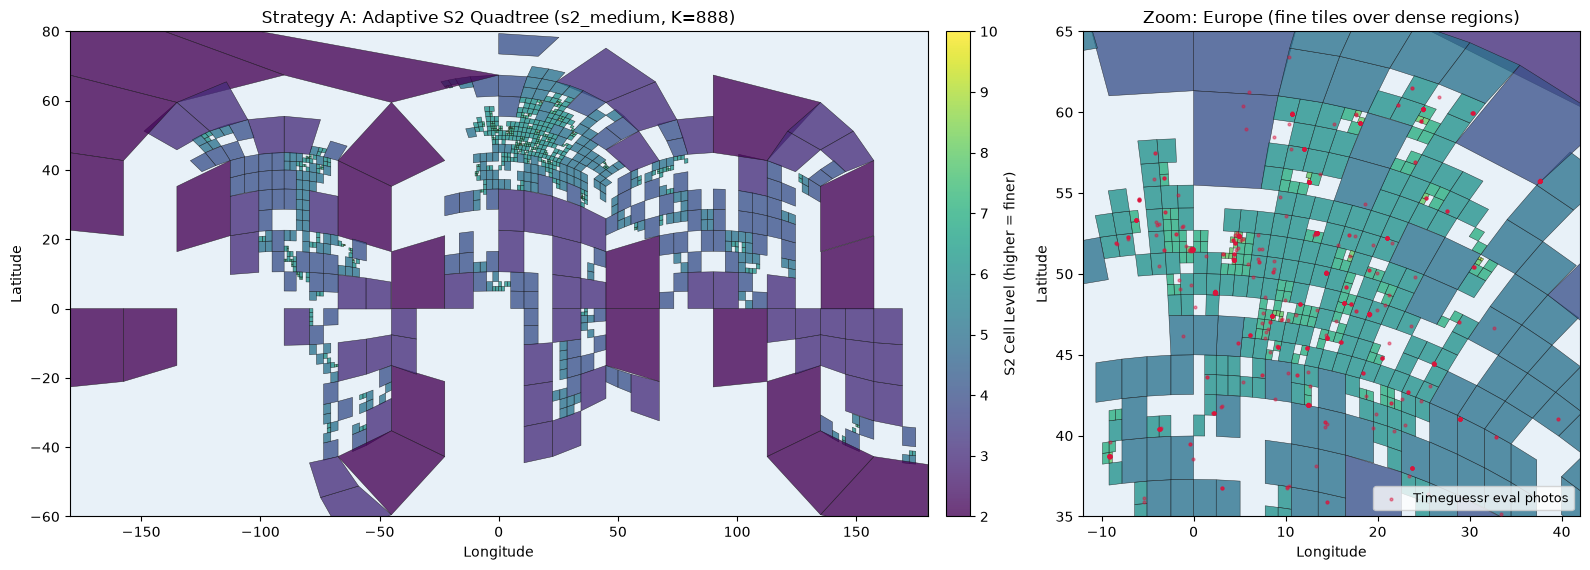

In [31]:
def plot_s2_cells_on_ax(ax, cells_df: pd.DataFrame, xlim=(-180, 180), ylim=(-65, 82), title=""):
    patches = []
    levels = []
    for _, row in cells_df.iterrows():
        cid = s2sphere.CellId.from_token(row["s2_token"])
        cell = s2sphere.Cell(cid)
        verts = [s2sphere.LatLng.from_point(cell.get_vertex(k)) for k in range(4)]
        lons_v = [v.lng().degrees for v in verts]
        lats_v = [v.lat().degrees for v in verts]
        # Skip antimeridian-wrapping edges so polygons don't streak across the map
        if max(lons_v) - min(lons_v) > 180:
            continue
        patches.append(mpatches.Polygon(list(zip(lons_v, lats_v)), closed=True))
        levels.append(row["s2_level"])

    pc = PatchCollection(patches, cmap="viridis", edgecolor="#111111", linewidth=0.35, alpha=0.78)
    pc.set_array(np.array(levels))
    ax.add_collection(pc)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_facecolor("#e8f1f8")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(title)
    return pc


fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), gridspec_kw={"width_ratios": [2.0, 1.1]})
pc1 = plot_s2_cells_on_ax(
    axes[0], s2_partitions["s2_medium"].cells_df,
    xlim=(-180, 180), ylim=(-60, 80),
    title=f"Strategy A: Adaptive S2 Quadtree (s2_medium, K={len(s2_partitions['s2_medium'].cells_df)})")
fig.colorbar(pc1, ax=axes[0], label="S2 Cell Level (higher = finer)", fraction=0.03, pad=0.02)

pc2 = plot_s2_cells_on_ax(
    axes[1], s2_partitions["s2_medium"].cells_df,
    xlim=(-12, 42), ylim=(35, 65),
    title="Zoom: Europe (fine tiles over dense regions)")
axes[1].scatter(
    tg_df["longitude"], tg_df["latitude"],
    s=4, c="crimson", alpha=0.45, label="Timeguessr eval photos", zorder=5
)
axes[1].legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

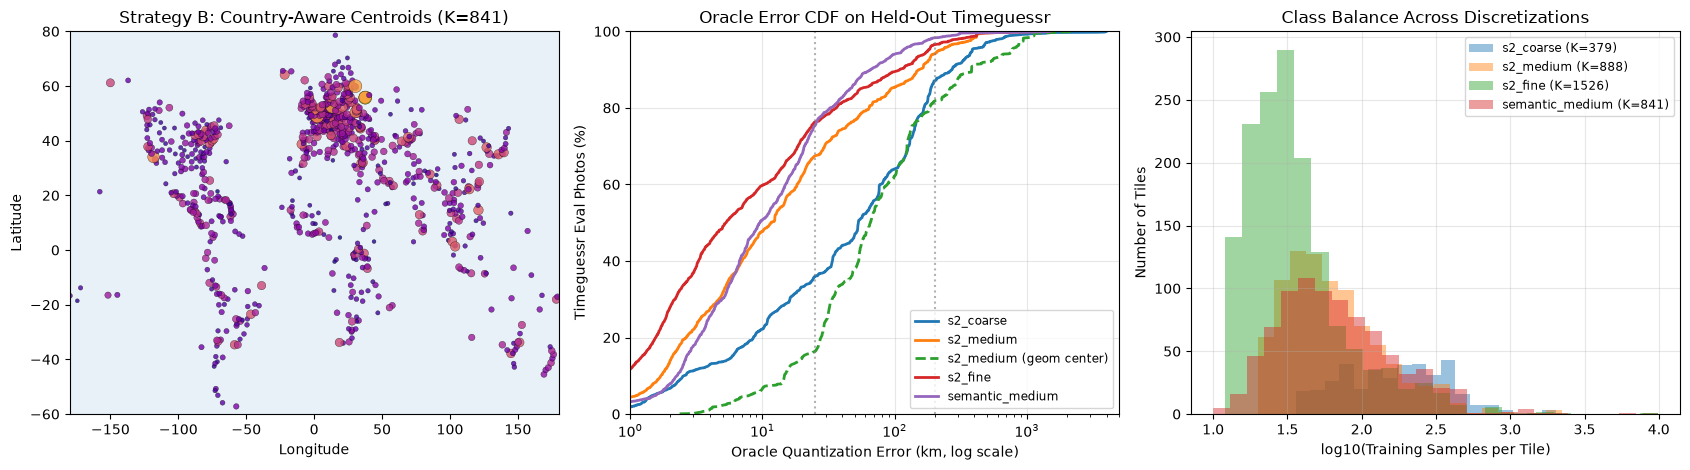

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# 1. Strategy B centroids map
sem_df = semantic_medium.cells_df
ax = axes[0]
ax.set_facecolor("#e8f1f8")
sc = ax.scatter(
    sem_df["centroid_lon"], sem_df["centroid_lat"],
    s=np.clip(np.sqrt(sem_df["train_count"]) * 2.2, 8, 90),
    c=np.log1p(sem_df["train_count"]), cmap="plasma", alpha=0.8, edgecolors="k", linewidths=0.25
)
ax.set_xlim(-180, 180)
ax.set_ylim(-60, 80)
ax.set_title(f"Strategy B: Country-Aware Centroids (K={len(sem_df)})")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

# 2. Quantization error CDF on held-out Timeguessr
ax = axes[1]
for label, dists in eval_dists.items():
    sorted_d = np.sort(dists)
    cdf = np.arange(1, len(sorted_d) + 1) / len(sorted_d) * 100.0
    ls = "--" if "geom" in label else "-"
    ax.plot(sorted_d, cdf, linestyle=ls, linewidth=2, label=label)
ax.set_xscale("log")
ax.set_xlim(1, 5000)
ax.set_ylim(0, 100)
ax.axvline(25, color="gray", linestyle=":", alpha=0.6)
ax.axvline(200, color="gray", linestyle=":", alpha=0.6)
ax.set_xlabel("Oracle Quantization Error (km, log scale)")
ax.set_ylabel("Timeguessr Eval Photos (%)")
ax.set_title("Oracle Error CDF on Held-Out Timeguessr")
ax.legend(fontsize=8.5, loc="lower right")
ax.grid(True, alpha=0.3)

# 3. Training samples per tile distribution
ax = axes[2]
for label, cdf in [
    ("s2_coarse", s2_partitions["s2_coarse"].cells_df),
    ("s2_medium", s2_partitions["s2_medium"].cells_df),
    ("s2_fine", s2_partitions["s2_fine"].cells_df),
    ("semantic_medium", semantic_medium.cells_df),
]:
    ax.hist(np.log10(cdf["train_count"]), bins=25, alpha=0.45, label=f"{label} (K={len(cdf)})")
ax.set_xlabel("log10(Training Samples per Tile)")
ax.set_ylabel("Number of Tiles")
ax.set_title("Class Balance Across Discretizations")
ax.legend(fontsize=8.5)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Export Discretizations & Unified Training/Eval Table for Notebooks 04 & 05

Saves to `data/tiling/`:
- `s2_coarse_cells.csv`, `s2_medium_cells.csv`, `s2_fine_cells.csv`, `semantic_medium_cells.csv` — tile lookup tables (centroids, S2 tokens, country lists for OCR masking).
- `dataset_with_tiles.csv` — unified metadata table for all 4 datasets with pre-assigned tile IDs (`s2_coarse_id`, `s2_medium_id`, `s2_fine_id`, `semantic_medium_id`) and a clean `split` column (`train` / `val` from external datasets, `test_timeguessr` for the held-out Timeguessr benchmark).
- `tiling_summary.json` — full configuration and oracle benchmark metrics.

In [33]:
# 1. Save individual cell lookup tables
for pname, part in s2_partitions.items():
    out_path = TILING_DIR / f"{pname}_cells.csv"
    part.cells_df.to_csv(out_path, index=False)
    print(f"Saved {len(part.cells_df):4,d} tiles -> {out_path}")

sem_path = TILING_DIR / "semantic_medium_cells.csv"
semantic_medium.cells_df.to_csv(sem_path, index=False)
print(f"Saved {len(semantic_medium.cells_df):4,d} tiles -> {sem_path}")

# 2. Build unified dataset with precomputed tile IDs and deterministic train/val/test split
rng = np.random.default_rng(SEED)
train_pool_export = train_pool_df[["image_path", "source", "year", "latitude", "longitude", "country"]].copy()
is_val = rng.random(len(train_pool_export)) < 0.10
train_pool_export["split"] = np.where(is_val, "val", "train")

tg_export = tg_df[["image_path", "source", "year", "latitude", "longitude", "country"]].copy()
tg_export["split"] = "test_timeguessr"

all_df = pd.concat([train_pool_export, tg_export], ignore_index=True)
all_lats = all_df["latitude"].to_numpy()
all_lons = all_df["longitude"].to_numpy()
all_ccs = all_df["country"].to_numpy()

for pname, part in s2_partitions.items():
    all_df[f"{pname}_id"] = part.assign_points(all_lats, all_lons)

# For training/val rows, assign semantic tiles within country; for test rows, nearest centroid
sem_ids = np.empty(len(all_df), dtype=np.int32)
train_mask = all_df["split"].isin(["train", "val"]).to_numpy()
sem_ids[train_mask] = semantic_medium.assign_points(all_lats[train_mask], all_lons[train_mask], countries=all_ccs[train_mask])
sem_ids[~train_mask] = semantic_medium.assign_points(all_lats[~train_mask], all_lons[~train_mask], countries=None)
all_df["semantic_medium_id"] = sem_ids

dataset_out = TILING_DIR / "dataset_with_tiles.csv"
all_df.to_csv(dataset_out, index=False)
print(f"\nSaved unified dataset ({len(all_df):,} rows) -> {dataset_out}")
print(all_df["split"].value_counts().to_dict())

# 3. Save summary JSON
summary_payload = {
    "split_country_alpha": SPLIT_COUNTRY_ALPHA,
    "s2_presets": S2_PRESETS,
    "semantic_target_tiles": target_k,
    "benchmark_results": eval_results,
}
summary_out = TILING_DIR / "tiling_summary.json"
summary_out.write_text(json.dumps(summary_payload, indent=2), encoding="utf-8")
print(f"Saved summary -> {summary_out}")

Saved  379 tiles -> d:\VSCodeProjects\CS441\data\tiling\s2_coarse_cells.csv
Saved  888 tiles -> d:\VSCodeProjects\CS441\data\tiling\s2_medium_cells.csv
Saved 1,526 tiles -> d:\VSCodeProjects\CS441\data\tiling\s2_fine_cells.csv
Saved  841 tiles -> d:\VSCodeProjects\CS441\data\tiling\semantic_medium_cells.csv

Saved unified dataset (98,240 rows) -> d:\VSCodeProjects\CS441\data\tiling\dataset_with_tiles.csv
{'train': 87056, 'val': 9584, 'test_timeguessr': 1600}
Saved summary -> d:\VSCodeProjects\CS441\data\tiling\tiling_summary.json
